   YearsExperience  Salary
0              1.1   39343
1              1.3   46205
2              1.5   37731
3              2.0   43525
4              2.2   39891
<class 'pandas.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 2 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   YearsExperience  30 non-null     float64
 1   Salary           30 non-null     int64  
dtypes: float64(1), int64(1)
memory usage: 612.0 bytes
None
       YearsExperience         Salary
count        30.000000      30.000000
mean          5.313333   76003.000000
std           2.837888   27414.429785
min           1.100000   37731.000000
25%           3.200000   56720.750000
50%           4.700000   65237.000000
75%           7.700000  100544.750000
max          10.500000  122391.000000
Training Score: 0.9645401573418146
Testing Score: 0.9024461774180497
Coefficient: [[9423.81532303]]
Intercept: [25321.58301178]


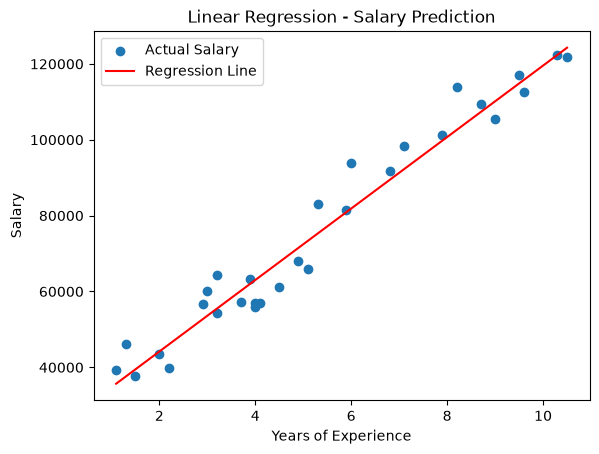

Estimated Salary for 5 years of experience: 72440.6596269317


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

# Read the dataset from Salary_Data.csv
df = pd.read_csv("Salary_Data.csv")

print(df.head())
print(df.info())
print(df.describe())

features = df[["YearsExperience"]].values
label = df[["Salary"]].values

x_train, x_test, y_train, y_test = train_test_split(
    features, label, test_size=0.2, random_state=42
)

model = LinearRegression()
model.fit(x_train, y_train)

print("Training Score:", model.score(x_train, y_train))
print("Testing Score:", model.score(x_test, y_test))
print("Coefficient:", model.coef_)
print("Intercept:", model.intercept_)

# Sort x-values before plotting the regression line
sort_order = np.argsort(features[:, 0])
sorted_features = features[sort_order]

plt.scatter(features, label, label="Actual Salary")
plt.plot(
    sorted_features,
    model.predict(sorted_features),
    color="red",
    label="Regression Line"
)

plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.title("Linear Regression - Salary Prediction")
plt.legend()
plt.show()

years = np.array([[5.0]])
salary = model.predict(years)

print("Estimated Salary for 5 years of experience:", salary[0][0])